# Worked example: the APOGEE DR19 example table

This notebook runs Starfold on a real table that has no labels. It reads the evidence in
physical units and ends with what the run supports and what it does not. It also redraws the
figures of the [APOGEE tutorial](https://andreaswneitzel.github.io/Starfold/tutorial/apogee.html)
in the manual.

The APOGEE DR19 example table holds 9,242 stars of the Milky Way, our own galaxy, in eight
columns. Three columns are chemical abundances and five describe each star's orbit around the
centre of the Galaxy.
The next sections explain where they come from. The sources, cuts and checksum of the table
are in the [provenance note](../bench/data/stellar_chemokinematics_apogee_dr19.md).

Treat the run as a check of the method, not as a finding about the Milky Way. The disc of the
Milky Way (the flat, rotating part in which the Sun sits) is known to hold two chemical
sequences. A method that finds no structure here, or fifty groups, has a problem. Finding the
known split without being told about it passes a sanity check and nothing more.

## Terms used here

The notebook is self-contained. Notebook 01 explains the same terms more slowly, on the
scikit-learn digits dataset, where the true classes are known. The manual's
[glossary](https://andreaswneitzel.github.io/Starfold/glossary.html) defines every term.

- **UMAP** (McInnes, Healy and Melville 2018, arXiv:1802.03426) draws a map of the stars in a
  few dimensions, in which stars with similar values in the table stay close. This map is
  also called an **embedding**.
- **HDBSCAN** (Campello, Moulavi and Sander 2013, doi:10.1007/978-3-642-37456-2_14) marks the
  dense regions of that map as groups. The stars between the regions get no group. This
  notebook calls them *unassigned* (notebook 01 says *noise*).
- **Optuna** (Akiba et al. 2019, arXiv:1907.10902) is the library that runs the search over
  settings. A **setting** is the six values that steer UMAP and HDBSCAN (listed in "The
  setting the search chose"). A **trial** is one setting that Optuna tries.
- **Seed.** A number that fixes every random choice, so that a run can be repeated exactly.
- **Score and gap.** Starfold scores a setting without any labels, on how well its groups
  survive resampling. It then subtracts the score of the same setting on a **structureless
  copy** of the table. The copy keeps every column's values and the overall correlation
  between columns, but has no groups. That difference is the **gap**.
- **Refit, world.** A refit is one more fit of the chosen setting on a random 80 percent of
  the stars, with a new seed. Starfold makes 32 and calls them *worlds* in the code
  (`result.worlds`). Every measure below named *recurrence*, *support*, *unresolved* or
  *stability interval* says how the 32 refits agree with each other and with the fit on all
  stars.
- **Flag.** A short named warning that Starfold attaches to a result. Not every flag is a
  fault.
- **p-value** (only in the last sections). The share of structureless copies whose best score
  reaches the table's, counting the table as one draw. It is not the probability that the
  groups are real.

At the default budgets, the recorded run took 163 seconds, 334 fits and 1,684 MB of host
memory on a laptop GPU (graphics card) with RAPIDS cuML, a GPU version of UMAP and HDBSCAN.
The CPU path has not been timed at this size. For a quick CPU pass on a random subsample, set
`N_ROWS = 3000`. The calibration test is off. It costs 102 fits per copy of the table, for up
to 19 copies (1,938 fits), about six times the rest of the run.

You need a clone of the repository, because the table ships with the repository and not with
the installed package. The first cell walks up from the current folder until it finds the
clone, and adds it to the Python path so that `bench` imports.

In [1]:
import sys
from pathlib import Path

here = Path.cwd().resolve()
ROOT = next((p for p in (here, *here.parents) if (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    msg = "Run this notebook from inside a clone of the starfold repository."
    raise FileNotFoundError(msg)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(f"repository root: {ROOT.name}")

repository root: starfold


The printed path is the root of your clone. If the cell raises an error instead, start the
notebook from a folder inside the clone.

## Parameters

These five values are the only ones you are meant to change.

- `RANDOM_STATE` is the seed of the whole run.
- `ENGINE = "auto"` uses cuML when it imports and sees a GPU, and otherwise warns and runs on
  the CPU. `"cuml"` fails instead of falling back.
- `N_JOBS` sets the number of worker processes on the CPU. It is forced to 1 on cuML.
- `N_ROWS` keeps a random subset of that many stars. `None` keeps all of them.
- `FIGURES = ROOT / "docs" / "figures"` rewrites the PNG figures of the manual. With `None`,
  nothing is written.

In [2]:
RANDOM_STATE = 0
ENGINE = "auto"
N_JOBS = 1
N_ROWS = None  # 3000 runs a seeded subsample, for a quick CPU pass
FIGURES = None

The next cell imports the libraries and sets up the output folder and a helper that saves
figures. It also refuses to write the manual's figures from a subsample.

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from bench.datasets import example_table
from matplotlib.lines import Line2D

import starfold
from starfold._engine import derive_seed
from starfold.backend import fit_pipeline
from starfold.consensus import coassociation
from starfold.prep import scale

if FIGURES is not None and N_ROWS is not None:
    msg = "The manual figures use every star; set N_ROWS = None to write them."
    raise ValueError(msg)
RUN = ROOT / "notebooks" / "runs" / ("apogee" if N_ROWS is None else f"apogee_{N_ROWS}")
TAB10 = plt.get_cmap("tab10")


def save_figure(fig, name):
    """Write a figure under FIGURES as a 150 dpi PNG; do nothing when FIGURES is None."""
    if FIGURES is None:
        return
    path = Path(FIGURES) / name
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")

## The table

Each row is one star, and each column is one number measured or derived for it. The columns
come from two surveys.

- **APOGEE** is a survey that recorded the infrared spectrum (the light split by wavelength)
  of hundreds of thousands of stars. DR19 is its 19th data release. Its **ASPCAP** pipeline
  fits each spectrum to measure the star's chemical make-up.
- **Gaia DR3** is the third data release of the Gaia space telescope, which measures the
  positions, distances and motions of stars on the sky. **galpy** is a Python package that
  follows each star's orbit in a model of the Galaxy's gravity.

The chemical columns are **abundance ratios**. [X/Y] is the base-10 logarithm of the ratio of
element X to element Y in the star, minus the same quantity for the Sun. Its unit is the
**dex** (one base-10 logarithm step): 0 dex is the Sun's ratio, and -1 dex is a tenth of it.

- `fe_h` is [Fe/H], iron relative to hydrogen. Astronomers call all elements heavier than
  helium "metals", so a star with low [Fe/H] is called *metal-poor*.
- `alpha_m` ([alpha/M]) and `mg_fe` ([Mg/Fe]) say how rich a star is in alpha elements, such
  as magnesium, compared with other metals or iron. Stars that formed early and quickly are
  richer in them.

The orbital columns use the kiloparsec (kpc), a distance unit for the Galaxy, and km/s.

- `J_R` and `J_z` are orbital actions in kpc km/s: how far the orbit swings in and out, and
  up and down through the disc.
- `L_z` is the angular momentum about the Galaxy's axis, large and positive for stars that
  rotate with the disc.
- `ecc` is the orbital eccentricity, 0 for a circle. `E` is the orbital energy in km^2/s^2,
  more negative for a star bound more tightly to the Galaxy.

Starfold rescales every column to mean 0 and variance 1 before UMAP. A column in kpc km/s
then does not outweigh one in dex only because its numbers are larger. The cell below loads
the table and prints each column's median and the range of its middle 90 percent.

In [4]:
x, names = example_table()
if N_ROWS is not None:
    rng = np.random.default_rng(RANDOM_STATE)
    x = x[np.sort(rng.choice(x.shape[0], size=N_ROWS, replace=False))]

UNITS = {
    "fe_h": "dex",
    "alpha_m": "dex",
    "mg_fe": "dex",
    "J_R": "kpc km/s",
    "J_z": "kpc km/s",
    "L_z": "kpc km/s",
    "ecc": "",
    "E": "km^2/s^2",
}
LABELS = {
    "fe_h": "[Fe/H] (dex)",
    "alpha_m": r"[$\alpha$/M] (dex)",
    "mg_fe": "[Mg/Fe] (dex)",
    "J_R": r"$J_R$ (kpc km s$^{-1}$)",
    "J_z": r"$J_z$ (kpc km s$^{-1}$)",
    "L_z": r"$L_z$ (kpc km s$^{-1}$)",
    "ecc": "eccentricity",
    "E": r"$E$ (km$^2$ s$^{-2}$)",
}
SHORT = {
    "fe_h": "[Fe/H]",
    "alpha_m": r"[$\alpha$/M]",
    "mg_fe": "[Mg/Fe]",
    "J_R": r"$J_R$",
    "J_z": r"$J_z$",
    "L_z": r"$L_z$",
    "ecc": "ecc",
    "E": r"$E$",
}


def fmt(value):
    """Three significant figures, or whole numbers with separators from 1,000 up."""
    return f"{value:,.0f}" if abs(value) >= 1000 else f"{value:.3g}"


low, middle, high = np.percentile(x, [5, 50, 95], axis=0)
print(f"{x.shape[0]:,} stars")
print(f"{'column':8}{'median':>10}{'5 to 95 percent':>26}  unit")
for j, name in enumerate(names):
    print(f"{name:8}{fmt(middle[j]):>10}{fmt(low[j]):>13} to {fmt(high[j]):>9}  {UNITS[name]}")

9,242 stars
column      median           5 to 95 percent  unit
fe_h        -0.138       -0.559 to     0.224  dex
alpha_m     0.0448      -0.0221 to     0.253  dex
mg_fe       0.0618      -0.0257 to     0.306  dex
J_R           29.4         2.21 to       162  kpc km/s
J_z           11.3        0.724 to        66  kpc km/s
L_z          1,857        1,204 to     2,334  kpc km/s
ecc          0.148       0.0402 to     0.365  
E         -155,907     -172,581 to  -144,186  km^2/s^2


Read each row as the typical value of a column and the range that holds 90 percent of the
stars. The columns span different scales (eccentricity below 1, energy in the hundreds of
thousands), which is why Starfold rescales them. Use this table later as the reference against
which each group's medians are compared.

## The run

The settings of UMAP and HDBSCAN can turn the same table into a handful of groups or into
hundreds, and the tools' defaults are only one guess. Starfold therefore searches for the
setting first and then measures how reproducible the result is. `recover` does this in five
steps.

1. **Search.** Optuna tries up to 48 settings (trials). Trial 0 is the library defaults.
   Trials 1 to 16 are a Sobol design: settings spread evenly over the allowed ranges, chosen
   without looking at any score. Later trials come from TPE (Bergstra et al. 2011), a sampler
   that proposes settings near the earlier good ones. From trial 17, a trial whose early
   scores fall below the median is pruned, meaning stopped early.
2. **Score.** Each trial is scored without labels on the same three random 80 percent subsets
   of the stars. The score asks how well a fit on one subset predicts the groups found on
   another, how many stars both fits assign, and how closely the groups follow the nearest
   neighbours in the table itself. The score never reads the number of groups.
3. **Choice.** The best few trials are scored again on fresh subsets, because the best of
   many noisy scores is partly luck. One setting is selected.
4. **Partition.** The selected setting is fitted once on all stars. That fit is the
   partition (the split of the stars into groups), `result.labels`.
5. **Refits.** Starfold then refits the selected setting 32 times on fresh 80 percent subsets
   with new seeds, to see which groups come back.

The manual's [pipeline page](https://andreaswneitzel.github.io/Starfold/concepts/pipeline.html)
draws these steps.

The cell below runs all five steps and saves the result to disk. It then prints the engine
used (`cuml` is the GPU library, `cpu` is the reference fallback), the number of
UMAP-plus-HDBSCAN fits, the time and the peak memory of the whole process. The two per-stage
lines break that down. `search` is steps 1 to 3, `reference` is the fit on all stars, `worlds`
the 32 refits, `consensus` the co-association check further down, and `null` the calibration
test, which is zero here because it is off.

In [5]:
CONFIG = starfold.Config()  # null_families is empty, so the calibration test is skipped
result = starfold.recover(x, config=CONFIG, random_state=RANDOM_STATE, engine=ENGINE, n_jobs=N_JOBS)
starfold.save(result, RUN)
kept = x[result.kept_rows]
engine = result.provenance["engine_resolved"]  # "cpu" or "cuml", as the stage functions need

provenance = result.provenance
print(
    f"engine {provenance['engine_resolved']}, {provenance['total_fits']} fits, "
    f"{provenance['stage_seconds']['total']:.0f} s, "
    f"peak host memory {provenance['peak_rss_mb']:,.0f} MB"
)
print("seconds per stage:", {k: round(v) for k, v in provenance["stage_seconds"].items()})
print("fits per stage:", provenance["stage_fits"])
print(f"saved to {RUN.relative_to(ROOT)}")

engine cuml, 334 fits, 163 s, peak host memory 1,684 MB
seconds per stage: {'search': 140, 'reference': 1, 'worlds': 13, 'consensus': 2, 'null': 0, 'total': 163}
fits per stage: {'search': 300, 'reference': 2, 'worlds': 32, 'null': 0}
saved to notebooks/runs/apogee


In the recorded run, the search took 140 of the 163 seconds and 300 of the 334 fits. Check
the engine line first: if it says `cpu` when you expected `cuml`, the GPU was not found (see
the manual's [GPU page](https://andreaswneitzel.github.io/Starfold/howto/use-gpu.html)).

## Flags

A flag is a short name for one weakness, limit or event of a run, derived from the stored
evidence, so that a script can check it. Starfold defines 17. A flag tells you where to look;
it is not always a fault. `null_not_run` is expected, because the calibration test was not
run. So is `consensus_subsampled` on all stars, because the co-association check below uses
4,096 of them. The cell prints each raised flag with a one-line reading. Terms in it, such as
unresolved mass and the co-association cut, are defined in the sections below. The manual
lists every flag on its
[flags page](https://andreaswneitzel.github.io/Starfold/reference/flags.html).

In [6]:
MEANING = {
    "search_stopped_early": "the best score stopped improving before the trial budget ran out",
    "search_budget_exhausted": "the search used every trial; a larger n_trials may help",
    "selected_is_default": "the library defaults won the search",
    "default_within_noise": "the winner and the defaults score within the comparison's noise",
    "no_groups_in_reference": "the fit on all stars found no groups",
    "high_unresolved_mass": "the mean unresolved mass is above 0.5",
    "count_unstable": "fewer than half the refits find the partition's number of groups",
    "search_trial_failures": "at least one search trial raised an error; see its error field",
    "world_fit_failures": "at least one refit raised an error; see result.worlds.world_errors",
    "consensus_subsampled": "the co-association check ran on a seeded subset of stars",
    "consensus_disagrees": "the cut of the co-association matrix agrees with the partition "
    "below 0.5",
    "null_not_run": "no calibration test ran, so there is no p-value; run starfold.null_test",
    "observed_statistic_zero": "the observed statistic is zero, so the test was skipped",
    "no_structure_supported": "the calibration test ran and p is above alpha",
    "backend_disagreement": "CPU and GPU fits of the selected setting disagree",
    "rows_rejected_nonfinite": "rows with missing or infinite values were dropped",
    "n_jobs_forced_to_one_on_cuml": "cuML runs in one process, so n_jobs was set to 1",
}
for flag in result.flags:
    print(f"{flag}: {MEANING.get(flag, 'see the manual')}")
if not result.flags:
    print("no flags raised")

search_budget_exhausted: the search used every trial; a larger n_trials may help
consensus_subsampled: the co-association check ran on a seeded subset of stars
consensus_disagrees: the cut of the co-association matrix agrees with the partition below 0.5
null_not_run: no calibration test ran, so there is no p-value; run starfold.null_test


The recorded run raised four flags. `consensus_subsampled` and `null_not_run` are expected.
`search_budget_exhausted` says the search used all 48 trials, so a larger budget might find a
better setting. `consensus_disagrees` is discussed under the co-association check below. None
of the four says that the groups are absent.

## Groups and how often they come back

The groups are those of the fit on all stars, `result.labels`, where -1 marks an unassigned
star. Three measures, each taken over the 32 refits, say how far you can trust them.

- **Group recurrence** (how often a group comes back). For one group, every refit is searched
  for the group that overlaps it best. The overlap is the Jaccard index: the stars the two
  share divided by the stars in either. 1 is identical membership and 0 is none. Recurrence is
  the average over refits, so 1 means the group comes back with the same members every time.
  The printed 5 to 95 percent band is the range of that overlap over refits. The help page
  of the R function `clusterboot` (Hennig, R package fpc) reads a mean of 0.85 and above as
  highly stable. It says a Jaccard of 0.5 or less in one resample means the cluster dissolved.
- **Count interval.** The number of groups each refit found, summarised by its 5th to 95th
  percentile. `interval 2 to 2` means both percentiles are 2, so nearly every refit found 2
  groups. It is a stability interval (the range over refits), not a confidence interval for
  a true number of groups.
- **Unresolved mass** (how much of the table the refits leave without a stable group). For a
  star and a refit that drew it, the score is 1 if the refit left the star unassigned.
  Otherwise it is the share of the star's refit group that the partition leaves unassigned.
  These scores are averaged over the star's refits, then over stars. 0 would mean that no
  refit ever left a star without a group, and 1 that every one did.

The manual explains each measure further:
[recurrence](https://andreaswneitzel.github.io/Starfold/metrics/recurrence.html),
[count interval](https://andreaswneitzel.github.io/Starfold/metrics/count-interval.html) and
[unresolved mass](https://andreaswneitzel.github.io/Starfold/metrics/unresolved.html).

In [7]:
worlds = result.worlds
groups = np.unique(result.labels[result.labels >= 0])
noise = result.labels < 0
if groups.size <= 10:
    colours = [TAB10(i) for i in range(groups.size)]
else:
    colours = [plt.get_cmap("viridis")(t) for t in np.linspace(0.0, 0.9, groups.size)]

print(f"{result.n_groups} groups; {noise.sum():,} of {noise.size:,} stars unassigned")
for i, g in enumerate(groups):
    low, high = worlds.group_recurrence_band[i]
    print(
        f"  group {g}: {np.sum(result.labels == g):,} stars, recurrence "
        f"{worlds.group_recurrence[i]:.3f} (5 to 95 percent over refits {low:.3f} to {high:.3f})"
    )
counts, frequency = np.unique(worlds.count_values, return_counts=True)
print(
    "groups per refit:",
    ", ".join(f"{c} in {f} refits" for c, f in zip(counts, frequency, strict=True)),
)
print(f"interval {worlds.count_interval[0]} to {worlds.count_interval[1]}")
print(f"unresolved mass {result.unresolved_mass:.3f}")

2 groups; 1,068 of 9,242 stars unassigned
  group 0: 1,588 stars, recurrence 0.914 (5 to 95 percent over refits 0.886 to 0.935)
  group 1: 6,586 stars, recurrence 0.918 (5 to 95 percent over refits 0.879 to 0.938)
groups per refit: 2 in 31 refits, 3 in 1 refits
interval 2 to 2
unresolved mass 0.154


In the recorded run, both groups have recurrence above the clusterboot 0.85 mark, with bands
that stay above it. 31 refits found 2 groups and one found 3, which falls outside the 5 to 95
percent interval. The unresolved mass of 0.154 means most stars keep a group across refits.
Together these say the split is reproducible under resampling. They do not say it is the true
split.

## The setting the search chose

A setting is six values.

- `n_neighbors` (UMAP): how many neighbouring stars UMAP looks at to place each star. Small
  values keep fine local structure, large values keep the broad layout. Default 15.
- `min_dist` (UMAP): how tightly UMAP may pack stars together on the map. Default 0.1.
- `n_components` (UMAP): the number of dimensions of the map that HDBSCAN then groups. It can
  be more than two. Default 2.
- `min_cluster_size` (HDBSCAN): the fewest stars that may form a group. Default 5.
- `min_samples` (HDBSCAN): how many neighbours a star needs to count as part of a dense
  region. Larger values leave more stars unassigned. Default 5.
- `selection_method` (HDBSCAN): `eom` prefers a few large groups, `leaf` prefers many small
  ones. Default `eom`.

Each trial's score has three terms.

- **Agreement**: how well a fit on one subset predicts the groups of stars it never saw,
  measured with the adjusted Rand index (ARI). An ARI of 1 is identical grouping and about 0
  is chance.
- **Coverage**: the share of stars that both fits assign to a group.
- **Modularity**: how much more often a star's nearest neighbours in the table share its group
  than chance would give.

The score is the cube root of their product, so a zero in any term makes it zero. The search
also scores the same setting on a structureless copy of the table and counts only the excess
over the copy, the gap. See the manual's
[score page](https://andreaswneitzel.github.io/Starfold/metrics/score.html).

The cell prints three versions of the setting as columns.

- `on subsets` is the setting as searched, on 80 percent of the stars.
- `all stars` is the one fitted to all of them. The star counts `min_cluster_size` and
  `min_samples` are scaled up by the ratio of the sizes, so that a group means the same
  fraction of the table in both.
- `defaults` is the library's own setting, for comparison.

The line below the table gives the trial counts: complete (all fits done), pruned (stopped
early), and completed after pruning (up to three pruned trials that were ahead of the best
are finished at the end). It also gives the reason the search stopped. `beats the defaults
under the objective` says only that the selected setting has a larger fresh gap than the
defaults, not that the difference exceeds the noise.

In [8]:
def show(value):
    """Floats to three significant figures, anything else as text."""
    return f"{value:.3g}" if isinstance(value, float) else str(value)


settings = (result.params, result.deployed_params, result.default_params)
print(f"{'':18}{'on subsets':>12}{'all stars':>12}{'defaults':>12}")
for field in result.params.to_dict():
    print(f"{field:18}" + "".join(f"{show(getattr(s, field)):>12}" for s in settings))
search = result.search
print(
    f"{len(search.trials)} trials: {search.n_completed} complete, {search.n_pruned} pruned, "
    f"{search.n_completed_after_prune} completed after pruning; stop: {search.stop_reason}"
)
print(f"beats the defaults under the objective: {search.beats_default_under_objective}")

                    on subsets   all stars    defaults
n_neighbors                 54          54          15
min_dist                 0.289       0.289         0.1
n_components                 2           2           2
min_cluster_size            72          90           5
min_samples                 24          30           5
selection_method           eom         eom         eom
48 trials: 39 complete, 9 pruned, 0 completed after pruning; stop: budget
beats the defaults under the objective: True


In the recorded run, the selected setting looks at far more neighbours than the default (54
against 15) and needs at least 72 stars per group on a subset (90 on all stars) against 5.
That is a setting tuned for broad structure. `stop: budget` matches the
`search_budget_exhausted` flag.

## The map

The next cell rebuilds the map so that you can plot it. When the selected setting draws its
map in two dimensions, the cell refits it on all stars with the same seed. It then checks that
the refit gives back exactly the same groups, so the picture is the map HDBSCAN cut. With more
dimensions, the cell instead draws a separate two-dimensional refit for display only, and says
so in the axis label. This display refit adds one UMAP fit on the CPU.

In [9]:
deployed = result.deployed_params
if deployed.n_components == 2:
    # seed id 4 is the seed recover uses for the fit on all stars
    fit = fit_pipeline(
        kept, deployed, seed=derive_seed(RANDOM_STATE, 4), engine=engine, scaling=CONFIG.scaling
    )
    np.testing.assert_array_equal(
        fit.labels, result.labels, err_msg="the refit did not reproduce the emitted groups"
    )
    layout = fit.embedding
    axis_note = "the map HDBSCAN cut"
else:
    import umap

    reducer = umap.UMAP(
        n_neighbors=deployed.n_neighbors,
        min_dist=deployed.min_dist,
        n_components=2,
        random_state=RANDOM_STATE,
    )
    layout = reducer.fit_transform(scale(kept, CONFIG.scaling))
    axis_note = f"display refit; groups cut in {deployed.n_components} dimensions"
print(f"layout: {axis_note}")

layout: the map HDBSCAN cut


`the map HDBSCAN cut` means the plot below shows the same map the groups were found on.

The next cell plots the map, one colour per group, with unassigned stars in grey. UMAP axes
have no units; only which stars sit near which matters. Opacity is each star's own support
(`worlds.own_support`), from 0 to 1. For each refit that drew the star, support is the share of
the star's refit group that sits in the star's own group of the partition, averaged over the
refits. A star that keeps company with the same stars every time is opaque. Faint stars are
the ones the refits place inconsistently or leave unassigned. Stars without a value are drawn
at the minimum opacity of 0.05. See the manual's
[support page](https://andreaswneitzel.github.io/Starfold/metrics/support.html).

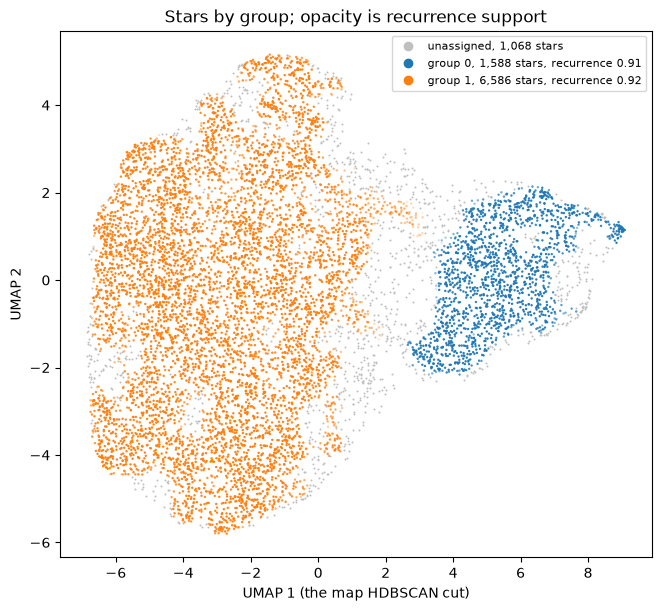

In [10]:
own = np.clip(np.nan_to_num(worlds.own_support, nan=0.0), 0.05, 1.0)
fig, ax = plt.subplots(figsize=(6.5, 6), layout="constrained")
ax.scatter(layout[noise, 0], layout[noise, 1], s=2, color="0.75", lw=0)
handles = [
    Line2D([], [], ls="", marker="o", color="0.75", label=f"unassigned, {noise.sum():,} stars")
]
for i, (g, colour) in enumerate(zip(groups, colours, strict=True)):
    members = result.labels == g
    rgba = np.tile(colour, (members.sum(), 1))
    rgba[:, 3] = own[members]
    ax.scatter(layout[members, 0], layout[members, 1], s=3, c=rgba, lw=0)
    label = f"group {g}, {members.sum():,} stars, recurrence {worlds.group_recurrence[i]:.2f}"
    handles.append(Line2D([], [], ls="", marker="o", color=colour, label=label))
ax.set_xlabel(f"UMAP 1 ({axis_note})")
ax.set_ylabel("UMAP 2")
ax.set_title("Stars by group; opacity is recurrence support")
ax.legend(handles=handles, fontsize=8)
save_figure(fig, "apogee/01_layout.png")
plt.show()

Look for faint bands along the edges between groups: those are the stars whose group changes
from refit to refit. Do not read distances between groups on a UMAP map as physical
distances; UMAP keeps neighbours, not overall scale.

## What the regions of the map are

The map has no units, so it cannot tell you what a region is. The next cell draws the same map
eight times, coloured once by each column. A region that is bright in one panel and dark in
another differs in those columns. Each colour scale is clipped to the column's 2nd to 98th
percentile, so that a long tail does not flatten the rest.

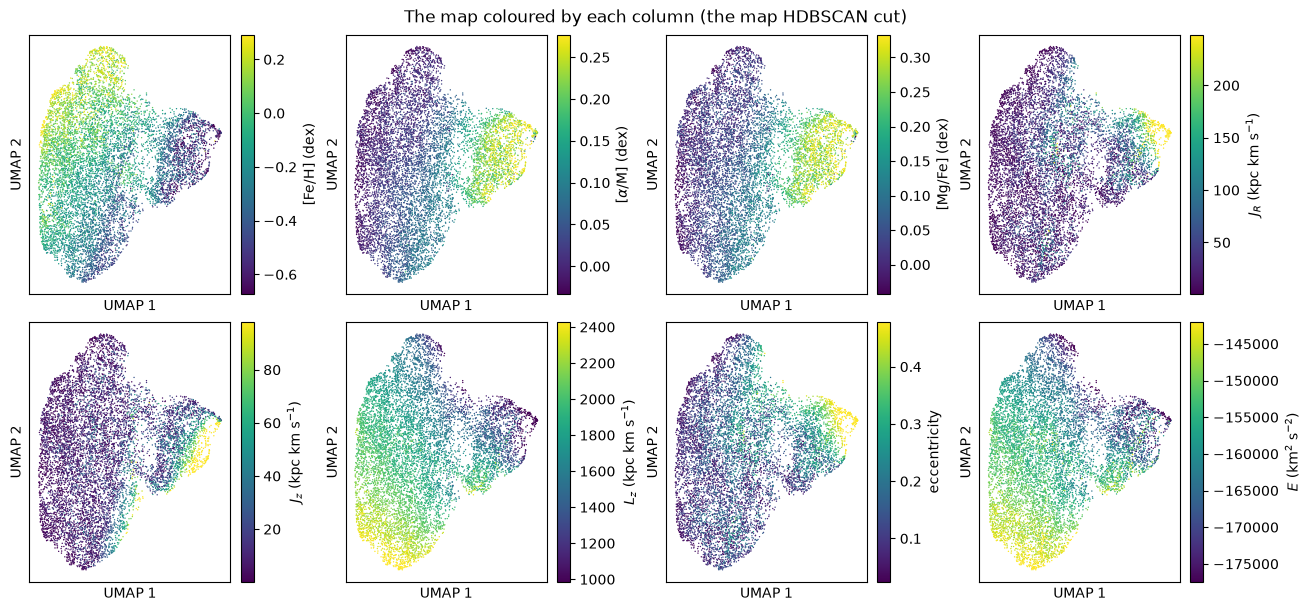

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6), layout="constrained")
for ax, name, values in zip(axes.flat, names, kept.T, strict=True):
    low, high = np.percentile(values, [2, 98])
    points = ax.scatter(
        layout[:, 0], layout[:, 1], c=values, s=1, lw=0, cmap="viridis", vmin=low, vmax=high
    )
    fig.colorbar(points, ax=ax, label=LABELS[name])
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"The map coloured by each column ({axis_note})")
save_figure(fig, "apogee/08_feature_layout.png")
plt.show()

Compare each panel with the group map above. A column whose colour changes sharply at the
border between groups is one that separates them; a column with no pattern there does not.

## The groups in physical units

The next cell describes each group in the original units of each column. In every refit, each
group is matched to its closest refit group (the one with the largest Jaccard overlap, as
above), and that refit group's median is taken in each column. The printout gives the median
of those medians over the 32 refits, their 5 to 95 percent range, and the median of all stars
for comparison. The range shows how much a group's median moves when the stars are resampled,
not how wide the group is. See the manual's
[properties page](https://andreaswneitzel.github.io/Starfold/metrics/properties.html).

In [12]:
median, band = worlds.property_median, worlds.property_band
overall = np.median(kept, axis=0)
for i, g in enumerate(groups):
    print(f"group {g}: median over refits (5 to 95 percent), then all stars")
    for j, name in enumerate(names):
        print(
            f"  {name:8}{fmt(median[i, j]):>9} ({fmt(band[i, j, 0])} to {fmt(band[i, j, 1])})"
            f"{fmt(overall[j]):>11}  {UNITS[name]}"
        )

group 0: median over refits (5 to 95 percent), then all stars
  fe_h       -0.416 (-0.424 to -0.405)     -0.138  dex
  alpha_m     0.222 (0.221 to 0.224)     0.0448  dex
  mg_fe       0.273 (0.271 to 0.275)     0.0618  dex
  J_R          79.3 (76 to 82.2)       29.4  kpc km/s
  J_z          32.6 (31.4 to 33.7)       11.3  kpc km/s
  L_z         1,474 (1,464 to 1,485)      1,857  kpc km/s
  ecc          0.26 (0.254 to 0.265)      0.148  
  E        -163,784 (-164,177 to -163,230)   -155,907  km^2/s^2
group 1: median over refits (5 to 95 percent), then all stars
  fe_h      -0.0758 (-0.0796 to -0.0709)     -0.138  dex
  alpha_m    0.0258 (0.0247 to 0.0272)     0.0448  dex
  mg_fe      0.0404 (0.0388 to 0.0418)     0.0618  dex
  J_R          23.4 (23 to 23.8)       29.4  kpc km/s
  J_z          8.55 (8.36 to 8.66)       11.3  kpc km/s
  L_z         1,926 (1,922 to 1,935)      1,857  kpc km/s
  ecc          0.13 (0.128 to 0.131)      0.148  
  E        -154,301 (-154,408 to -154,095)   -15

Read each line as: this group's typical value, how much that value moves across refits, and
the typical value of all stars. In the recorded run, group 0 has a median [Fe/H] of -0.416 dex
against -0.138 for all stars, and a median [Mg/Fe] of 0.273 against 0.0618. Its ranges are
narrow compared with those differences, so the difference between the groups does not come
from resampling alone.

The next cell plots the same numbers. In the left panel, every star appears in the
[Fe/H]-[Mg/Fe] plane, with each group's median and its 5 to 95 percent range over refits. The
right panel puts all eight columns on one axis, as each group's median minus the table mean,
in units of the table's standard deviation (the typical spread of a column).

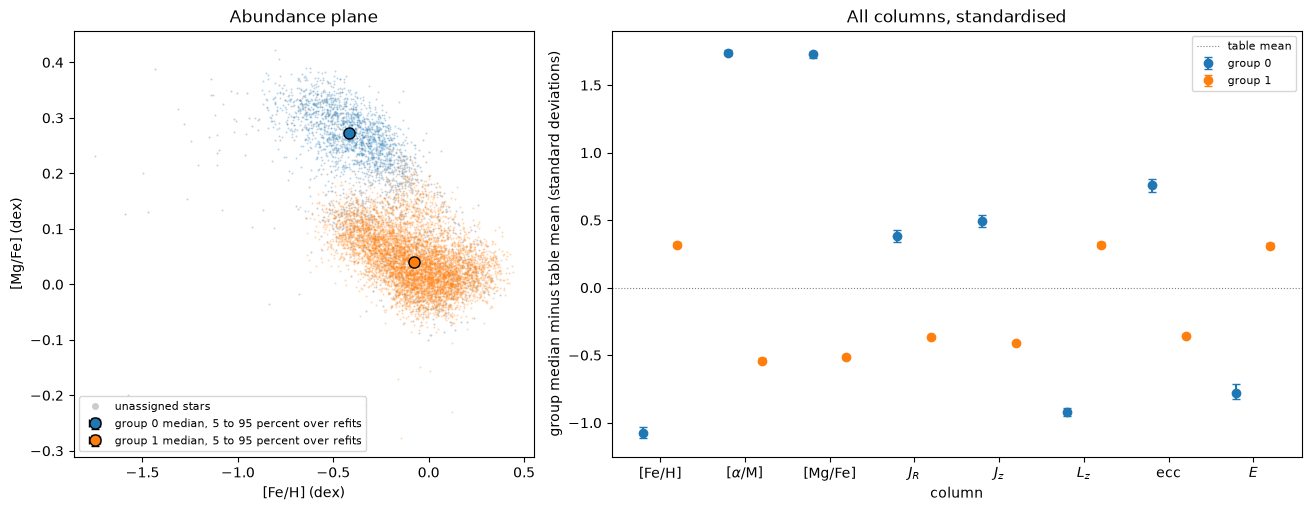

In [13]:
def spans(value, low, high):
    """Errorbar lengths below and above a value, never negative."""
    return np.clip([np.atleast_1d(value - low), np.atleast_1d(high - value)], 0.0, None)


fe, mg = names.index("fe_h"), names.index("mg_fe")
centre, spread = kept.mean(axis=0), kept.std(axis=0)
positions = np.arange(len(names))
offsets = np.linspace(-0.2, 0.2, groups.size) if groups.size > 1 else np.zeros(groups.size)
fig, (plane, panel) = plt.subplots(
    1, 2, figsize=(13, 5), width_ratios=(1, 1.5), layout="constrained"
)
plane.scatter(kept[noise, fe], kept[noise, mg], s=2, color="0.8", lw=0)
plane_handles = [Line2D([], [], ls="", marker="o", ms=4, color="0.8", label="unassigned stars")]
for i, (g, colour) in enumerate(zip(groups, colours, strict=True)):
    members = result.labels == g
    plane.scatter(kept[members, fe], kept[members, mg], s=2, color=colour, alpha=0.3, lw=0)
    marker = plane.errorbar(
        median[i, fe],
        median[i, mg],
        xerr=spans(median[i, fe], *band[i, fe]),
        yerr=spans(median[i, mg], *band[i, mg]),
        fmt="o",
        ms=8,
        mfc=colour,
        mec="k",
        ecolor="k",
        capsize=3,
        label=f"group {g} median, 5 to 95 percent over refits",
    )
    plane_handles.append(marker)
    z = (median[i] - centre) / spread
    z_band = (band[i] - centre[:, None]) / spread[:, None]
    panel.errorbar(
        positions + offsets[i],
        z,
        yerr=spans(z, z_band[:, 0], z_band[:, 1]),
        fmt="o",
        ms=6,
        color=colour,
        capsize=3,
        label=f"group {g}",
    )
plane.set_xlabel(LABELS["fe_h"])
plane.set_ylabel(LABELS["mg_fe"])
plane.set_title("Abundance plane")
plane.legend(handles=plane_handles, fontsize=8)
panel.axhline(0.0, color="0.5", lw=0.8, ls=":", label="table mean")
panel.set_xticks(positions, [SHORT[name] for name in names])
panel.set_xlabel("column")
panel.set_ylabel("group median minus table mean (standard deviations)")
panel.set_title("All columns, standardised")
panel.legend(fontsize=8)
save_figure(fig, "apogee/04_properties.png")
plt.show()

In the right panel, a point far above or below the dotted line marks a column in which that
group differs from the table as a whole. The bars show how far a group's median moves over
the 32 refits. They are stability intervals, not confidence intervals. They contain no
measurement error (the uncertainty of each measured value), because the table has no
per-star uncertainties.

## Reading the groups

The Milky Way disc has two chemical sequences in the [Fe/H]-[Mg/Fe] plane (Bensby et al. 2014,
doi:10.1051/0004-6361/201322631; Hayden et al. 2015, doi:10.1088/0004-637X/808/2/132). The
high-alpha sequence holds older, metal-poorer stars on hotter orbits (orbits that stray further
from a circle in the disc): lower `L_z`, and larger `J_R`, `J_z` and eccentricity. The
low-alpha sequence reaches solar [Fe/H] and above, on cooler, more circular orbits. Starfold
was told none of this.

A group that is high in both alpha columns, low in [Fe/H] and `L_z`, and high in `J_R`, `J_z`
and eccentricity sits on the high-alpha sequence. A group with the reverse pattern sits on the
low-alpha sequence. Use the right panel above to make that comparison for all eight columns at
once. If the groups match the two sequences, the method has passed its sanity check.

## Co-association: a check that ignores label numbers

Group numbers are arbitrary: one refit's group 0 may be another's group 1. This check needs no
matching of numbers, since it asks only whether two stars share a group.

Take the refits that sampled and assigned both stars of a pair. Their co-association is the
share of those refits that put the two in the same group. Pairs in the same group of the
partition should sit near 1, and pairs in different groups near 0. A pair no refit assigned
together counts as 0. With 32 refits the largest value is 1 - 1/64, because the underlying
distance is floored at 1/64 so that perfectly recurrent pairs keep a finite distance. The
contrast is the mean within groups minus the mean between groups. It is high when the groups
hold, and it does not depend on how each refit numbers its groups. See the manual's
[co-association page](https://andreaswneitzel.github.io/Starfold/metrics/coassociation.html).

The check also cuts the co-association matrix into groups of its own (the "cut"). It runs
HDBSCAN once more, with the co-association turned into a distance, and compares that cut with
the partition. The agreement is the ARI between the two times the share of stars that both
assign, and `consensus_disagrees` is raised below 0.5. The cut is a second clustering, though,
and can fail where the pair frequencies still separate the groups clearly, so read the
contrast first.

The check uses a seeded subset of 4,096 stars, because the pair matrices for all 9,242 stars
would exceed the 512 MiB memory budget. Their size grows with the square of the number of
stars.

The next cell computes the co-association of every pair in the subset and prints the two means,
the contrast and the cut agreement. It then draws a histogram split into pairs inside a group
and pairs in different groups. The vertical axis is the density of pairs on a logarithmic
scale, so that rare values can be seen. Pairs that include an unassigned star are left out.

4,096 stars (seeded subset): within 0.979, between 0.003, contrast 0.976, cut agreement 0.000


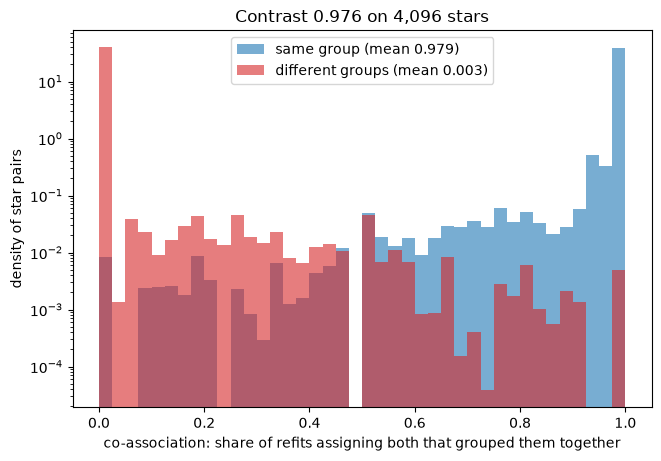

In [14]:
consensus = result.consensus
rows = consensus.rows
together = coassociation(worlds.world_labels, rows, engine=engine)
np.subtract(1.0, together, out=together)  # distance to co-association
reference = result.labels[rows]
pairs = np.logical_and.outer(reference >= 0, reference >= 0)
np.fill_diagonal(pairs, val=False)
same = np.equal.outer(reference, reference)
within, between = together[pairs & same], together[pairs & ~same]
del together, pairs, same

print(
    f"{consensus.n_rows:,} stars{' (seeded subset)' if consensus.subsampled else ''}: "
    f"within {consensus.within_association:.3f}, between {consensus.between_association:.3f}, "
    f"contrast {consensus.contrast:.3f}, cut agreement {consensus.agreement:.3f}"
)
fig, ax = plt.subplots(figsize=(6.5, 4.5), layout="constrained")
bins = np.linspace(0.0, 1.0, 41)
for values, colour, kind, mean in (
    (within, TAB10(0), "same group", consensus.within_association),
    (between, TAB10(3), "different groups", consensus.between_association),
):
    if values.size:
        ax.hist(
            values,
            bins=bins,
            density=True,
            alpha=0.6,
            color=colour,
            label=f"{kind} (mean {mean:.3f})",
        )
ax.set_yscale("log")
ax.set_xlabel("co-association: share of refits assigning both that grouped them together")
ax.set_ylabel("density of star pairs")
ax.set_title(f"Contrast {consensus.contrast:.3f} on {consensus.n_rows:,} stars")
ax.legend()
save_figure(fig, "apogee/07_consensus.png")
plt.show()

Two well-separated humps, one near 1 for pairs in the same group and one near 0 for pairs in
different groups, mean the refits keep the partition's pairs together. In the recorded run the
contrast is 0.976 while the cut agreement is 0.000. The cut failed, as the warning above
allows, and raised `consensus_disagrees`. The contrast, which needs no cut, still supports the
split.

## Score on the data against score on a copy

Every trial was scored twice on the same subsets, once on the data and once on a structureless
copy of the table. Starfold's default generator of copies is a Gaussian copula: every column
keeps exactly its measured values, and the overall correlation between columns is kept. The
values are rearranged among the stars so that one smooth, elliptical cloud remains and there
are no groups. Notebook 03 and the manual's
[copies page](https://andreaswneitzel.github.io/Starfold/concepts/copies-and-gaps.html) explain
it. Whatever a setting scores on the copy, it scores without any structure. The search ranks
settings by the difference (the gap).

In the figure, the horizontal axis is the score on the data and the vertical axis the score on
the copy. A point below the dashed diagonal has a positive gap, and a point on it gains nothing
from the data. The colours say how the trial was proposed: the Sobol design, TPE, and pruned
trials finished at the end because they were ahead of the best. The star is the library
defaults and the ring is the selected trial.

The points are the search's own scores. The best score of many noisy trials is partly luck,
and that inflates the winner's gap (the winner's curse). For the final choice, the top three
and the defaults are therefore re-scored on fresh subsets against three fresh copies, and the
largest fresh gap is kept. That is why the selected trial need not be the point farthest from
the diagonal. The cell prints the fresh gaps under the figure.

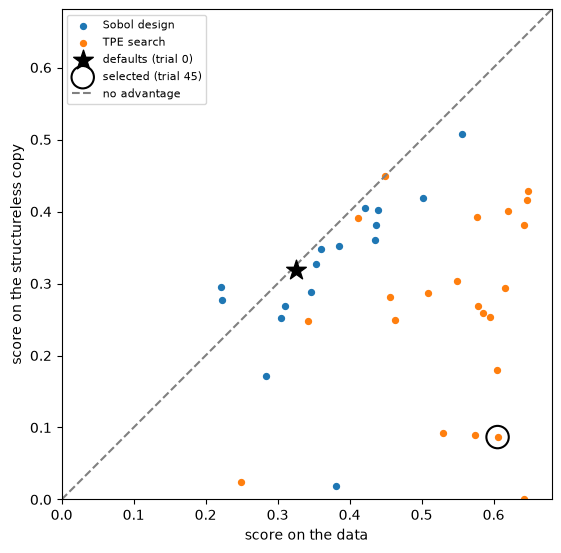

fresh gap over three fresh copies: selected 0.372, defaults -0.001


In [15]:
selected = next(t for t in search.trials if t.number == search.candidates[0].trial_number)
default = search.trials[0]
complete = [t for t in search.trials if t.state == "complete"]
PHASES = {
    "exploration": (TAB10(0), "Sobol design"),
    "convergence": (TAB10(1), "TPE search"),
    "completion": (TAB10(2), "completed after pruning"),
}
fig, ax = plt.subplots(figsize=(5.5, 5.5), layout="constrained")
for phase, (colour, label) in PHASES.items():
    scored = [t for t in complete if t.phase == phase]
    if scored:
        ax.scatter(
            [t.raw_score for t in scored],
            [t.null_score for t in scored],
            s=18,
            color=colour,
            label=label,
        )
ax.scatter(
    default.raw_score,
    default.null_score,
    marker="*",
    s=220,
    color="k",
    zorder=3,
    label="defaults (trial 0)",
)
ax.scatter(
    selected.raw_score,
    selected.null_score,
    s=260,
    facecolors="none",
    edgecolors="k",
    linewidths=1.5,
    zorder=4,
    label=f"selected (trial {selected.number})",
)
limit = 1.05 * np.nanmax([[t.raw_score, t.null_score] for t in complete])
ax.plot([0.0, limit], [0.0, limit], ls="--", color="0.5", label="no advantage")
ax.set(xlim=(0.0, limit), ylim=(0.0, limit), aspect="equal")
ax.set_xlabel("score on the data")
ax.set_ylabel("score on the structureless copy")
ax.legend(loc="upper left", fontsize=8)
save_figure(fig, "apogee_gap.png")
plt.show()
print(
    f"fresh gap over three fresh copies: selected {search.gap_selected:.3f}, "
    f"defaults {search.gap_default:.3f}"
)

In the recorded run, the fresh gap is 0.372 for the selected setting and -0.001 for the
defaults. The defaults gain nothing from the data over a structureless copy, while the
selected setting does. This is why Starfold searches instead of using the defaults.

## The calibration test, as its own step

The search picks the best of many settings, and the best of many settings scores well even on
data with no groups. The calibration test asks how often structureless data would look as good.

- **Statistic.** The best gap reached by the 17-trial exploration (the defaults and the 16
  Sobol points).
- **Copies.** The test computes the same statistic on copies of the table. Each gap needs 6
  fits per trial, so a copy costs 102 fits.
- **p-value.** (h + 1) / (L + 1), with L the copies run and h the copies at or above the
  table (Phipson and Smyth 2010, doi:10.2202/1544-6115.1585).
- **Stopping.** The test stops at 19 copies (1,938 fits), or as soon as 3 copies score at
  least as high as the data (Besag and Clifford 1991, doi:10.1093/biomet/78.2.301). With 19
  copies the smallest possible p-value is 0.05.

The p-value is valid only for the family of copies that was simulated. It is not the
probability that the groups are real. Run the test once, on the result you report, with the
same config, seed and engine:

```python
null = starfold.null_test(
    kept, result.search, config=CONFIG, random_state=RANDOM_STATE, engine=engine
)
print(null.p_value, null.p_intervals, null.structure_supported)
```

Here `result.null.skipped_reason` is `"null_not_run"`, and its p-value of 1.0 is a
placeholder, not a measurement. From the repository root,
`python -m bench.null_stage apogee notebooks/runs/apogee` runs the test on this table and
writes `bench/results/apogee_null.json`. The command reloads the full table, so it works on
the all-stars run only. Notebook 03 shows how to attach the test to a saved result. The
manual covers the test on its
[p-value page](https://andreaswneitzel.github.io/Starfold/metrics/calibration-p.html).

## How to report it

The reference run (all stars, `RANDOM_STATE = 0`, default budgets, laptop GPU) gave the values
below. A different engine or machine can change the last digits, because floating-point
operations run in a different order. The rows are explained under the table.

| quantity | value |
|---|---|
| groups, stars in each, unassigned | 2 groups of 1,588 and 6,586 stars; 1,068 unassigned |
| groups per refit, 5 to 95 percent over 32 refits | 2 to 2 |
| group recurrence | 0.91 (0.89 to 0.94) and 0.92 (0.88 to 0.94) |
| unresolved mass | 0.154 |
| co-association within, between, contrast | 0.979, 0.003, 0.976 |
| group medians of [Fe/H] and [Mg/Fe] (dex) | group 0: -0.42 and +0.27; group 1: -0.08 and +0.04 |
| regrouping agreement | 0.0, all 4,096 subset stars cut as noise |
| calibration p-value and interval | 0.10 (0.001 to 0.260), 1 of 19 copies at or above |

Reading the rows:

- *groups, stars in each, unassigned*: the partition, from the one fit on all stars.
- *groups per refit*: the count interval over the 32 refits. "2 to 2" means nearly every
  refit found two groups (31 of 32 in this run).
- *group recurrence*: the mean best Jaccard overlap of each group with the refit groups, with
  its 5 to 95 percent band over refits. Both groups are above the clusterboot 0.85 mark.
- *unresolved mass*: on average, 15 percent of a star's refit outcomes were "no group".
- *co-association within, between, contrast*: the refits that assigned both stars of a pair
  put them together 98 percent of the time for pairs in the same group, and 0.3 percent of the
  time for pairs in different groups. The contrast is 0.976.
- *group medians*: the medians of [Fe/H] and [Mg/Fe] in each group, in dex. Group 0 is
  metal-poorer and richer in magnesium than group 1.
- *regrouping agreement*: the cut of the co-association matrix (see the check above) assigned
  every one of the 4,096 subset stars to no group. Its agreement with the partition is
  therefore 0, and `consensus_disagrees` is raised. This is the failure of the cut that the
  check warns about. It is not evidence that the groups are absent: the contrast, which needs
  no cut, is 0.976.
- *calibration p-value and interval*: 1 of the 19 copies scored at or above the table, so
  p = (1 + 1) / (19 + 1) = 0.10. The interval is a 95 percent Clopper-Pearson interval
  (Clopper and Pearson 1934, doi:10.1093/biomet/26.4.404), an exact interval for a proportion
  from a small count. Here the proportion is the chance that a copy reaches the table's value,
  given 1 of 19. The interval is wide, 0.001 to 0.260, because 19 copies are few. It says how
  well Monte Carlo sampling (repeated random simulation) pinned the p-value, not how sure you
  can be that the groups are real. Since p is above 0.05, the test does not support structure
  at that level for this family of copies.

When you report the run, name the evidence behind each number. The groups come from one fit
of the selected setting on all stars. Recurrence, the count interval and the bands come from
32 refits on 80 percent subsets with new seeds. The p-value comes from the separate
calibration run in `bench/results/apogee_null.json`. It compares the best score of the
17-trial exploration on the data with the same exploration on structureless copies. The
manual's
[reporting page](https://andreaswneitzel.github.io/Starfold/howto/report-your-result.html)
gives a template.

What the run supports:

- How reproducible the split is. Recurrence and the count interval say how often the same
  groups come back when a fifth of the stars and the seeds change.
- How the groups differ in physical units (property table and figure), and how much those
  differences move across refits.
- A sanity check of the method, when the group medians fall on the two alpha sequences: a
  known feature of the disc, recovered with no labels and no astronomy in the method.

What it does not support:

- That the groups are distinct populations. Reproducible is not true, and the calibration
  test does not show it either. p at or below 0.05 says only that no copy keeping each
  column's values and the correlations between columns scored as high as the table. p above
  0.05 says at least one did.
- That the Milky Way holds this many populations. The count depends on the settings and on
  what you call a population, and its interval is over refits, not a confidence interval.
- A membership probability for each star. Support counts how often a star recurs with its
  group, and HDBSCAN's strengths describe one fit. Neither is a posterior (the probability of
  membership given the data and a stated model).
- Anything about the Galaxy as a whole. These are APOGEE stars with a signal-to-noise ratio
  above 70 (the strength of a star's spectrum compared with its random noise) and Gaia orbits
  inside a volume cut (only stars within a fixed region of space). No selection function
  (the chance that a star of a given kind enters the sample) was modelled.
- Anything about measurement error. With no per-star uncertainties in the table, the bands
  reflect subsampling and seeds only. `X_err`, an optional table of per-star uncertainties
  passed to `recover`, adds a new measurement draw to every refit (see the manual's
  [measurement-error
  page](https://andreaswneitzel.github.io/Starfold/howto/measurement-errors.html)).
- A citable result. The bundled table is for tutorials. For published work, rebuild it from
  APOGEE and Gaia.